In [1]:
import numpy as np
import os
import tensorflow as tf

SEED = 31415

def set_seed(seed=SEED):
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    os.environ['TF_DETERMINISTIC_OPS'] = '1'
    
set_seed()

2025-02-04 09:59:41.573569: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1738663181.596674   60424 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1738663181.604298   60424 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-02-04 09:59:41.630363: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import matplotlib.pyplot as plt
import warnings

from matplotlib import gridspec

plt.rc('figure', autolayout=True)
plt.rc('axes', labelweight='bold', labelsize='large',
       titleweight='bold', titlesize=18, titlepad=10)
plt.rc('image', cmap='magma')

warnings.filterwarnings("ignore")

In [3]:
from tensorflow.keras.preprocessing import image_dataset_from_directory

BATCH_SIZE = 64
IMAGE_SIZE = [128, 128]

ds_train_ = image_dataset_from_directory(
    '../datasets/car-or-truck/train',
    labels='inferred',
    label_mode='binary',
    image_size=IMAGE_SIZE,
    interpolation='nearest',
    batch_size=BATCH_SIZE,
    shuffle=True,
)

ds_valid_ = image_dataset_from_directory(
    '../datasets/car-or-truck/valid',
    labels='inferred',
    label_mode='binary',
    image_size=IMAGE_SIZE,
    interpolation='nearest',
    batch_size=BATCH_SIZE,
    shuffle=False,
)

def convert_to_float(image, label):
    image = tf.image.convert_image_dtype(image, dtype=tf.float32)
    return image, label

AUTOTUNE = tf.data.experimental.AUTOTUNE
ds_train = (
    ds_train_
    .map(convert_to_float)
    .cache()
    .prefetch(buffer_size=AUTOTUNE)
)
ds_valid = (
    ds_valid_
    .map(convert_to_float)
    .cache()
    .prefetch(buffer_size=AUTOTUNE)
)

Found 5117 files belonging to 2 classes.


2025-02-04 09:59:45.629045: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Found 5051 files belonging to 2 classes.


In [4]:
from tensorflow import keras
from tensorflow.keras import layers

FILTERS = 32
ReLU, SIGMOID = 'relu', 'sigmoid'
PADDING = 'same'

model = keras.Sequential([
    # Input 
    layers.Input(shape=[*IMAGE_SIZE, 3]),
    
    # First Convolutional Block
    layers.Conv2D(filters=FILTERS, kernel_size=5, activation=ReLU, padding=PADDING),
    layers.MaxPool2D(),

    # Second Convolutional Block
    layers.Conv2D(filters=2*FILTERS, kernel_size=3, activation=ReLU, padding=PADDING),
    layers.MaxPool2D(),

    # Third Convolutional Block
    layers.Conv2D(filters=4*FILTERS, kernel_size=3, activation=ReLU, padding=PADDING),
    layers.MaxPool2D(),

    # Classifier Head
    layers.Flatten(),
    layers.Dense(units=6, activation=ReLU),
    layers.Dense(units=1, activation=SIGMOID),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │       196,614 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             7 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291,405 (1.11 MB)

 Trainable params: 291,405 (1.11 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
EPOCHS = 40

model.compile(
    optimizer=tf.keras.optimizers.Adam(epsilon=0.01),
    loss='binary_crossentropy',
    metrics=['binary_accuracy']
)

history = model.fit(
    ds_train,
    validation_data=ds_valid,
    epochs=EPOCHS,
    verbose=1,
)

Epoch 1/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 133s 2s/step - binary_accuracy: 0.5724 - loss: 0.6813 - val_binary_accuracy: 0.6116 - val_loss: 0.6577
Epoch 2/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 121s 2s/step - binary_accuracy: 0.6258 - loss: 0.6526 - val_binary_accuracy: 0.6062 - val_loss: 0.6510
Epoch 3/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 165s 2s/step - binary_accuracy: 0.6377 - loss: 0.6403 - val_binary_accuracy: 0.5997 - val_loss: 0.6565
Epoch 4/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 97s 1s/step - binary_accuracy: 0.6500 - loss: 0.6285 - val_binary_accuracy: 0.6167 - val_loss: 0.6448
Epoch 5/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 98s 1s/step - binary_accuracy: 0.6658 - loss: 0.6133 - val_binary_accuracy: 0.6371 - val_loss: 0.6273
Epoch 6/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 97s 1s/step - binary_accuracy: 0.6928 - loss: 0.5951 - val_binary_accuracy: 0.6739 - val_loss: 0.5981
Epoch 7/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 97s 1s/step - binary_accuracy: 0.7005 - loss: 0.5802 - val_binary_accuracy: 0.6868 - val_loss: 0.5839
Epoch 8/40
80/80 

<Axes: >

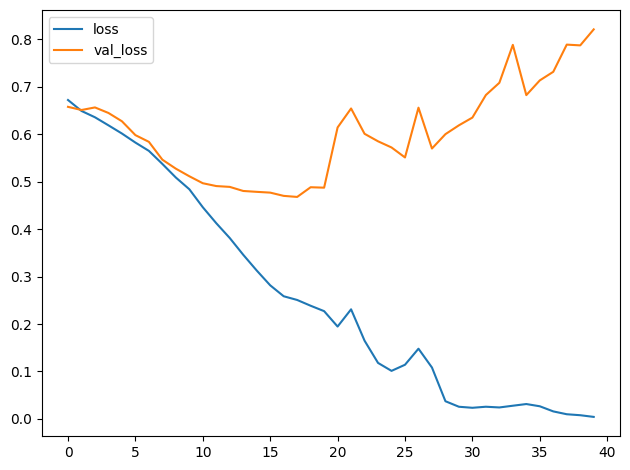

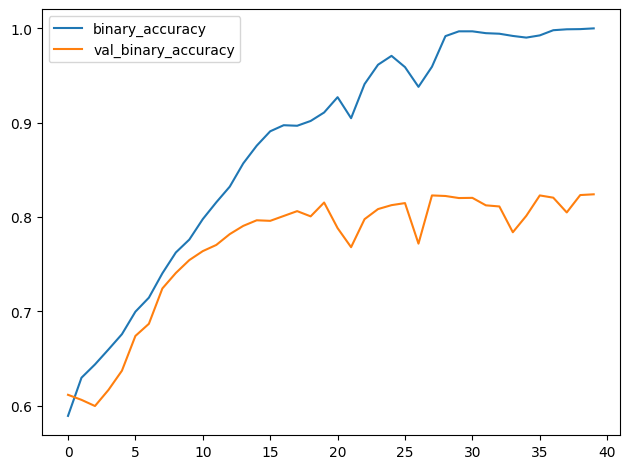

In [6]:
import pandas as pd

history_frame = pd.DataFrame(history.history)
history_frame.loc[:, ['loss', 'val_loss']].plot()
history_frame.loc[:, ['binary_accuracy', 'val_binary_accuracy']].plot()